# ДЗ2 — Cassava: проверка двух гипотез

**Единый протокол:** ResNet-18 с весами ImageNet, seed=18, resize=128, batch=128, 40 эпох, AdamW lr=1e-3, weight_decay=0.01, нормализация ImageNet. Заморозка — прежняя функция по первым 70% тензоров параметров (это не 70% числа скалярных весов). BatchNorm сохраняет прежнее поведение: статистики обновляются в train.

Используем фиксированную стратифицированную подвыборку 4000 изображений и один стратифицированный split 80/20 (random_state=18): 3200 train и 800 validation. Это подвыборка для ускоренного сравнения, а не оценка на полном датасете. Состав подвыборки и разбиения сохраняется в CSV.

Четыре варианта: baseline / H1 / H2 / H1+H2. Во всех одинаковые train/validation, число эпох, инициализация модели и порядок train-примеров. Веса классов считаются только по train; validation без аугментаций. Чекпойнт выбирается по val macro F1. Каждый вариант обучаем ровно один раз. Выводим метрики на общем validation, без итогового mean ± std.

40 эпох оставлены как в предыдущем baseline-ноутбуке. Если нужен лимит 12–15 эпох, его надо одинаково изменить в baseline и всех вариантах ДЗ2 и пересчитать результаты. Результаты старого baseline с другим seed, размером или набором данных для этого сравнения не подходят.

## Гипотезы

**H1 — взвешенный CrossEntropy для дисбаланса классов.** Веса w_c = N_train / (K × n_c) увеличивают вклад редких классов в loss. Проверяем, повышается ли macro F1 относительно baseline, а также precision/recall/F1 CBB и CGM. Возможен компромисс: рост recall редких классов при снижении precision или качества CMD; прирост не гарантирован.

**H2 — аугментации для устойчивости к освещению.** В train используем исходный фиксированный набор: RandomHorizontalFlip(p=0.5) + ColorJitter(0.2, 0.2, 0.2, 0.05). Проверяем рост F1 Healthy и macro F1, а также снижение доли Healthy → болезнь. Такие ошибки сами по себе не доказывают, что причина именно в затемнениях. Этот опыт оценивает пакет аугментаций целиком; вклад цветокоррекции отдельно от flip он не выделяет.

**Абляции:** baseline / only_h1 / only_h2 / full_h1_h2. Сравнение full с only_h1 показывает вклад H2 при включённой H1; full с only_h2 — вклад H1 при включённой H2. Каждый одиночный вариант также сравниваем с baseline.

In [ ]:
import os
import random
import json
import hashlib
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision
import sklearn
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torchvision import transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, confusion_matrix
from sklearn.preprocessing import label_binarize
from tqdm.auto import tqdm
from IPython.display import display

SEED, SIZE, BATCH, EPOCHS, LR = 18, 128, 128, 40, 1e-3
SUBSET_SIZE, FREEZE_RATIO = 4000, 0.7
VAL_SIZE = 0.2
WEIGHT_DECAY = 0.01
NUM_WORKERS = 0 
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLASSES = ["CBB", "CBSD", "CGM", "CMD", "Healthy"]
gt_path = Path("../data/train.csv")
train_path = Path("../data/cassava_train")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
OUT_DIR = Path("hw2_results_single_split")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything(SEED)
df = pd.read_csv(GT_PATH)
assert df["image_id"].is_unique, "Повторяющиеся image_id: проверьте данные до разбиения"
assert len(df) >= SUBSET_SIZE, "В CSV меньше 4000 изображений"
if len(df) > SUBSET_SIZE:
    df, _ = train_test_split(df, train_size=SUBSET_SIZE, stratify=df["label"], random_state=SEED)
df = df.reset_index(drop=True)
assert set(df["label"]) == set(range(len(CLASSES)))
assert df["label"].value_counts().min() >= 2
tr_df, va_df = train_test_split(
    df, test_size=VAL_SIZE, stratify=df["label"], random_state=SEED
)
manifest = df.copy()
manifest["split"] = "train"
manifest.loc[va_df.index, "split"] = "val"
assert set(tr_df["image_id"]).isdisjoint(set(va_df["image_id"]))
manifest.to_csv(OUT_DIR / "subset_and_split.csv", index=False)
tr_df = tr_df.reset_index(drop=True)
va_df = va_df.reset_index(drop=True)
config = {
    "seed": SEED, "size": SIZE, "batch": BATCH, "epochs": EPOCHS,
    "lr": LR, "weight_decay": WEIGHT_DECAY, "freeze_ratio": FREEZE_RATIO,
    "val_size": VAL_SIZE, "subset_size": len(df), "num_workers": NUM_WORKERS,
    "train_size": len(tr_df), "validation_size": len(va_df),
    "mean": MEAN, "std": STD, "device": str(DEVICE),
    "augmentation": "RandomHorizontalFlip(0.5) + ColorJitter(0.2, 0.2, 0.2, 0.05)",
    "training_seed": SEED,
    "manifest_sha256": hashlib.sha256(manifest.to_csv(index=False).encode()).hexdigest(),
    "torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
    "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
    "python": platform.python_version(), "platform": platform.platform(),
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else str(DEVICE),
    "deterministic_warn_only": True,
}
(OUT_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2))
print(f"Изображений: {len(df)}, train: {len(tr_df)}, val: {len(va_df)}, device={DEVICE}")
display(pd.crosstab(manifest["split"], manifest["label"]))

Изображений: 4000, train: 3200, val: 800, device=cuda


label,0,1,2,3,4
split,,,,,
train,162,327,357,1968,386
val,41,82,89,492,96


In [2]:
class CassavaDS(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        base = [T.Resize((SIZE, SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)]
        aug = [T.RandomHorizontalFlip(), T.ColorJitter(0.2, 0.2, 0.2, 0.05)] if augment else []
        self.tf = T.Compose(aug + base)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        x = self.tf(Image.open(TRAIN_PATH / row["image_id"]).convert("RGB"))
        return x, int(row["label"])

def freeze_most(model, ratio=0.7):
    params = list(model.parameters())
    n = len(params)
    for i, p in enumerate(params):
        p.requires_grad = i >= int(ratio * n)

def class_weights(tr):
    c = np.bincount(tr["label"].values, minlength=len(CLASSES)).astype(np.float64)
    assert np.all(c > 0), "В train отсутствует класс"
    w = len(tr) / (len(CLASSES) * c)
    return torch.tensor(w, dtype=torch.float32, device=DEVICE)


def classification_metrics(y_true, y_pred, prob):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(CLASSES)), average="macro", zero_division=0
    )
    y_bin = label_binarize(y_true, classes=range(len(CLASSES)))
    return {
        "f1_macro": f1,
        "precision_macro": p,
        "recall_macro": r,
        "pr_auc_macro": average_precision_score(y_bin, prob, average="macro"),
    }


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    ys, probs = [], []
    total_loss, total_samples = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        total_loss += criterion(logits, y).item() * y.size(0)
        total_samples += y.size(0)
        ys.append(y.cpu().numpy())
        probs.append(logits.softmax(1).cpu().numpy())
    y_true = np.concatenate(ys)
    prob = np.vstack(probs)
    y_pred = prob.argmax(1)
    metrics = classification_metrics(y_true, y_pred, prob)
    metrics["loss"] = total_loss / total_samples
    return metrics, y_true, y_pred, prob


def per_class_table(y_true, y_pred):
    p, r, f1, n = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(CLASSES)), zero_division=0
    )
    return pd.DataFrame(
        {"precision": p, "recall": r, "f1": f1, "support": n}, index=CLASSES
    )

In [3]:
def save_ckpt(path, state_dict, meta):
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": state_dict, **meta}, path)


def train_split(tr, va, *, run_seed, class_weights_flag=False, augment=False,
                desc="train", ckpt_path=None):
    seed_everything(run_seed)
    train_generator = torch.Generator().manual_seed(run_seed)
    val_generator = torch.Generator().manual_seed(run_seed + 10000)
    tr_ld = DataLoader(CassavaDS(tr, augment=augment), batch_size=BATCH, shuffle=True,
                       num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                       worker_init_fn=seed_worker, generator=train_generator)
    va_ld = DataLoader(CassavaDS(va, augment=False), batch_size=BATCH, shuffle=False,
                       num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                       worker_init_fn=seed_worker, generator=val_generator)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    freeze_most(model, FREEZE_RATIO)
    model = model.to(DEVICE)
    opt = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR, weight_decay=WEIGHT_DECAY)
    weights = class_weights(tr) if class_weights_flag else None
    crit = nn.CrossEntropyLoss(weight=weights)
    val_crit = nn.CrossEntropyLoss()  # одинаковый validation loss для всех вариантов
    best_f1, best, best_epoch = -1.0, None, None
    history = []
    for ep in tqdm(range(EPOCHS), desc=desc):
        model.train()
        total_loss, total_samples = 0.0, 0
        train_true, train_pred = [], []
        for x, y in tqdm(tr_ld, desc=f"ep {ep + 1}/{EPOCHS}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits = model(x)
            loss = crit(logits, y)
            loss.backward()
            opt.step()
            # У weighted CE знаменатель — сумма весов целевых классов.
            denominator = y.size(0) if weights is None else weights[y].sum().item()
            total_loss += loss.item() * denominator
            total_samples += denominator
            train_true.extend(y.detach().cpu().tolist())
            train_pred.extend(logits.detach().argmax(1).cpu().tolist())
        _, _, train_f1, _ = precision_recall_fscore_support(
            train_true, train_pred, labels=range(len(CLASSES)), average="macro", zero_division=0
        )
        val_metrics, _, _, _ = evaluate(model, va_ld, val_crit)
        history.append({
            "epoch": ep + 1,
            "train_loss": total_loss / total_samples,
            "train_f1_macro": train_f1,
            **{f"val_{k}": v for k, v in val_metrics.items()},
        })
        f1 = val_metrics["f1_macro"]
        if f1 > best_f1:
            best_f1, best_epoch = f1, ep + 1
            best = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if ckpt_path is not None:
                save_ckpt(ckpt_path, best, {"val_f1_macro": best_f1, "epoch": best_epoch})
        tqdm.write(
            f"{desc} ep {ep + 1}: train loss={history[-1]['train_loss']:.4f}, "
            f"val loss={val_metrics['loss']:.4f}, val F1={f1:.4f} (best={best_f1:.4f})"
        )
    model.load_state_dict(best)
    metrics, yt, yp, prob = evaluate(model, va_ld, val_crit)
    return {
        **metrics, "best_epoch": best_epoch,
        "per_class": per_class_table(yt, yp),
        "history": pd.DataFrame(history),
        "y_true": yt, "y_pred": yp, "prob": prob,
        "ckpt_path": str(ckpt_path) if ckpt_path is not None else None,
    }

### Четыре эксперимента на общем стратифицированном split
Baseline пересчитывается здесь, чтобы сравнение соответствовало текущей подвыборке и настройкам. Каждый вариант обучается один раз на тех же tr_df/va_df. Полный запуск — 4 × 40 = 160 эпох. История, лучший чекпойнт и validation-предсказания сохраняются отдельно для каждого варианта. Train loss у H1 использует веса классов, поэтому его абсолютные значения напрямую с невзвешенным train loss не сравниваем; validation loss везде одинаковый.

In [4]:
EXPS = [
    ("baseline", "Без весов классов и аугментаций", False, False),
    ("only_h1", "H1: взвешенный CrossEntropy", True, False),
    ("only_h2", "H2: аугментации", False, True),
    ("full_h1_h2", "H1+H2", True, True),
]
summary_rows = []
histories, per_class, cms, val_predictions = {}, {}, {}, {}
for name, hypothesis, cw, aug in EXPS:
    exp_dir = OUT_DIR / name
    exp_dir.mkdir(parents=True, exist_ok=True)
    result = train_split(
        tr_df, va_df, run_seed=SEED,
        class_weights_flag=cw, augment=aug, desc=name,
        ckpt_path=exp_dir / "best.pt",
    )
    histories[name] = result["history"]
    result["history"].to_csv(exp_dir / "history.csv", index=False)
    yt, yp, prob = result["y_true"], result["y_pred"], result["prob"]
    assert np.array_equal(yt, va_df["label"].to_numpy())
    pc = result["per_class"]
    healthy_mask = yt == CLASSES.index("Healthy")
    healthy_error_rate = (yp[healthy_mask] != CLASSES.index("Healthy")).sum() / healthy_mask.sum()
    summary_rows.append({
        "name": name, "hypothesis": hypothesis, "seed": SEED,
        "class_weights": cw, "augment": aug, "best_epoch": result["best_epoch"],
        **{k: result[k] for k in ["loss", "f1_macro", "precision_macro", "recall_macro", "pr_auc_macro"]},
        "f1_healthy": pc.loc["Healthy", "f1"],
        "healthy_to_disease_rate": healthy_error_rate,
        "ckpt_path": result["ckpt_path"],
    })
    per_class[name], cms[name] = pc, confusion_matrix(yt, yp, labels=range(len(CLASSES)))
    predictions = va_df.copy()
    predictions["prediction"] = yp
    for k, label in enumerate(CLASSES):
        predictions[f"prob_{label}"] = prob[:, k]
    predictions.to_csv(exp_dir / "val_predictions.csv", index=False)
    pc.to_csv(exp_dir / "val_per_class.csv")
    val_predictions[name] = predictions
    # Сохраняем сводку после каждого завершённого эксперимента.
    log = pd.DataFrame(summary_rows)
    base_f1 = log.loc[log["name"] == "baseline", "f1_macro"].iloc[0]
    log["delta_f1"] = log["f1_macro"] - base_f1
    log.to_csv(OUT_DIR / "experiments_hw2.csv", index=False)
    print(f"{name}: метрики по классам на validation")
    display(pc)

print("Метрики на общем validation и разность macro F1 с baseline:")
display(log)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 218MB/s]


baseline:   0%|          | 0/40 [00:00<?, ?it/s]

ep 1/40:   0%|          | 0/25 [00:00<?, ?it/s]

baseline ep 1: train loss=1.0768, val loss=0.9848, val F1=0.3368 (best=0.3368)


ep 2/40:   0%|          | 0/25 [00:00<?, ?it/s]

... (316 outputs left out)

full_h1_h2 ep 40: train loss=0.0282, val loss=2.0641, val F1=0.4273 (best=0.4727)
full_h1_h2: метрики по классам на validation


,precision,recall,f1,support
CBB,0.411765,0.512195,0.456522,41
CBSD,0.353982,0.487805,0.410256,82
CGM,0.464286,0.146067,0.222222,89
CMD,0.824903,0.861789,0.842942,492
Healthy,0.436170,0.427083,0.431579,96


Метрики на общем validation и разность macro F1 с baseline:


,name,hypothesis,seed,class_weights,augment,best_epoch,loss,f1_macro,precision_macro,recall_macro,pr_auc_macro,f1_healthy,healthy_to_disease_rate,ckpt_path,delta_f1
0,baseline,Без весов классов и аугментаций,18,False,False,4,1.511985,0.440488,0.471085,0.438578,0.448604,0.329114,0.729167,hw2_results_single_split/baseline/best.pt,0.000000
1,only_h1,H1: взвешенный CrossEntropy,18,True,False,33,1.686235,0.471242,0.488292,0.465777,0.442209,0.417910,0.562500,hw2_results_single_split/only_h1/best.pt,0.030754
2,only_h2,H2: аугментации,18,False,True,16,2.018599,0.472024,0.503986,0.460532,0.466906,0.317241,0.760417,hw2_results_single_split/only_h2/best.pt,0.031536
3,full_h1_h2,H1+H2,18,True,True,4,1.214801,0.472704,0.498221,0.486988,0.454205,0.431579,0.572917,hw2_results_single_split/full_h1_h2/best.pt,0.032216


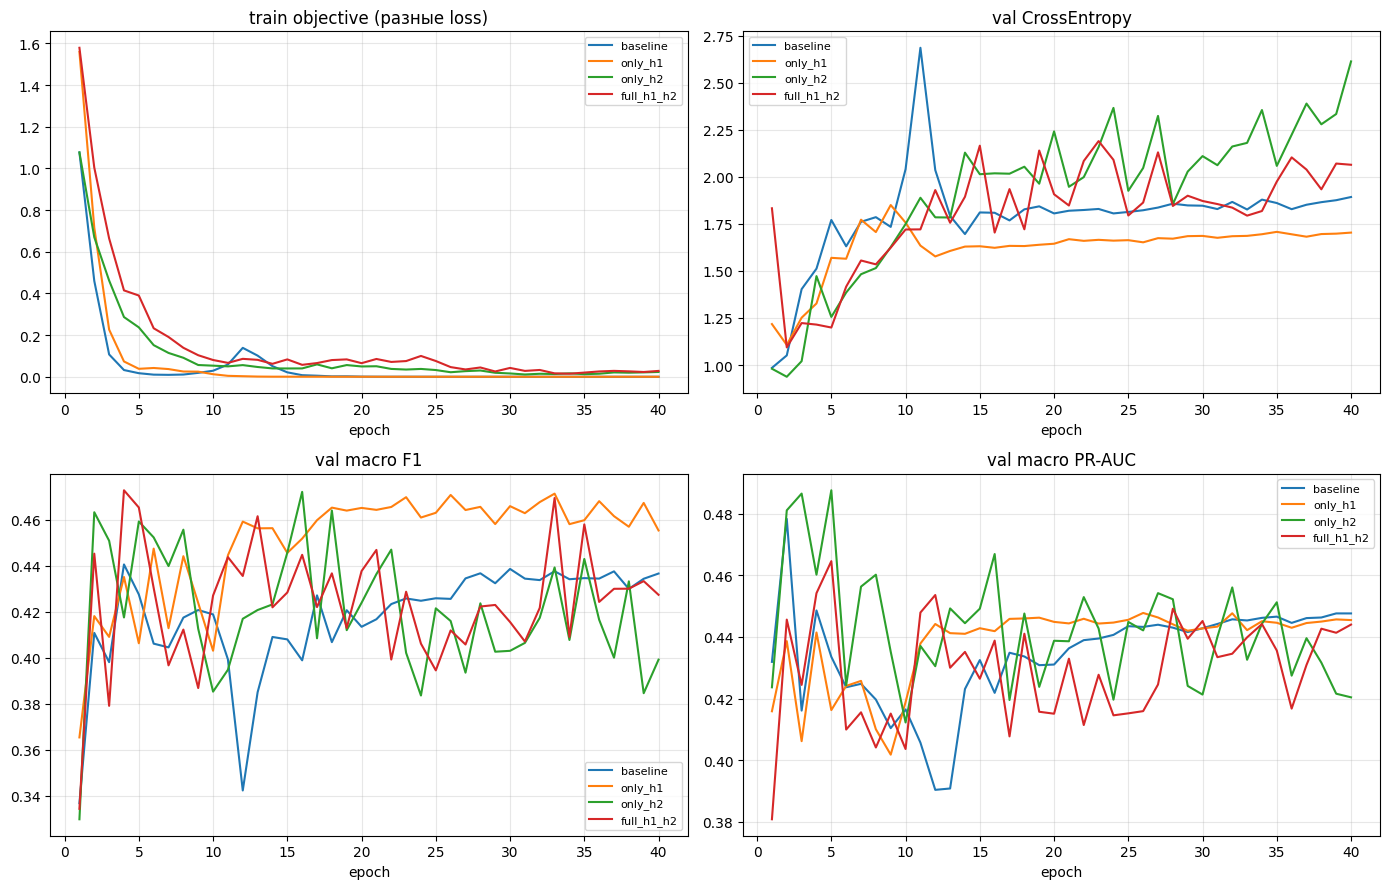

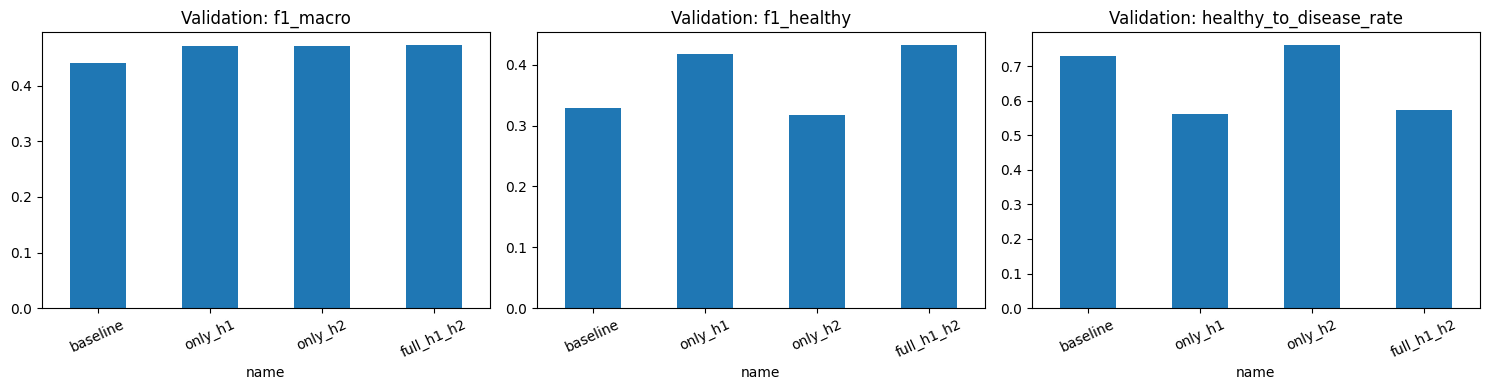

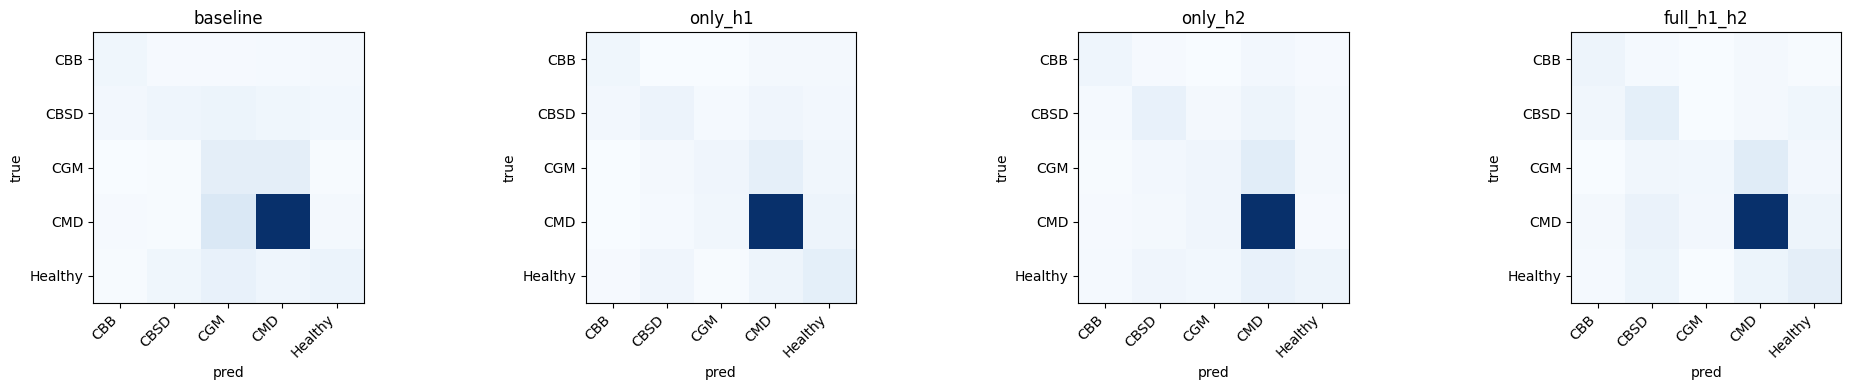

baseline                               only_h1                      \
        precision    recall        f1 support precision    recall        f1   
CBB      0.432432  0.390244  0.410256      41  0.418605  0.439024  0.428571   
CBSD     0.413043  0.231707  0.296875      82  0.402985  0.329268  0.362416   
CGM      0.256250  0.460674  0.329317      89  0.392157  0.224719  0.285714   
CMD      0.834343  0.839431  0.836879     492  0.827715  0.898374  0.861598   
Healthy  0.419355  0.270833  0.329114      96  0.400000  0.437500  0.417910   

                  only_h2                             full_h1_h2            \
        support precision    recall        f1 support  precision    recall   
CBB          41  0.512195  0.512195  0.512195      41   0.411765  0.512195   
CBSD         82  0.430380  0.414634  0.422360      82   0.353982  0.487805   
CGM          89  0.311475  0.213483  0.253333      89   0.464286  0.146067   
CMD         492  0.796491  0.922764  0.854991     492   0.824903  0.861789   
Healthy      96  0.469388  0.239583  0.317241      96   0.436170  0.427083   

                           
               f1 support  
CBB      0.456522      41  
CBSD     0.410256      82  
CGM      0.222222      89  
CMD      0.842942     492  
Healthy  0.431579      96

In [5]:
# Графики читают сохранённую историю; эту ячейку можно запускать повторно.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for name, _, _, _ in EXPS:
    h = pd.read_csv(OUT_DIR / name / "history.csv")
    axes[0, 0].plot(h["epoch"], h["train_loss"], label=name)
    axes[0, 1].plot(h["epoch"], h["val_loss"], label=name)
    axes[1, 0].plot(h["epoch"], h["val_f1_macro"], label=name)
    axes[1, 1].plot(h["epoch"], h["val_pr_auc_macro"], label=name)
for ax, title in zip(axes.ravel(), ["train objective (разные loss)", "val CrossEntropy", "val macro F1", "val macro PR-AUC"]):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "training_curves.png", dpi=160)
plt.show()

log = pd.read_csv(OUT_DIR / "experiments_hw2.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["f1_macro", "f1_healthy", "healthy_to_disease_rate"]):
    log.set_index("name")[metric].plot.bar(ax=ax)
    ax.set_title(f"Validation: {metric}")
    ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(OUT_DIR / "val_comparison.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, len(EXPS), figsize=(5 * len(EXPS), 4), squeeze=False)
for ax, (name, _, _, _) in zip(axes.ravel(), EXPS):
    pred = pd.read_csv(OUT_DIR / name / "val_predictions.csv")
    cm = confusion_matrix(pred["label"], pred["prediction"], labels=range(len(CLASSES)))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), labels=CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), labels=CLASSES)
    ax.set_xlabel("pred")
    ax.set_ylabel("true")
    ax.set_title(name)
fig.tight_layout()
plt.show()
display(pd.concat({name: pd.read_csv(OUT_DIR / name / "val_per_class.csv", index_col=0)
                   for name, _, _, _ in EXPS}, axis=1))

## Оценка гипотез и выводы



| Вариант | Macro F1 | Δ к baseline | F1 Healthy | Healthy → болезнь |
|---|---:|---:|---:|---:|
| Baseline | 0.4405 | — | 0.3291 | 72.9% |
| H1: веса классов | 0.4712 | +0.0308 | 0.4179 | 56.2% |
| H2: аугментации | 0.4720 | +0.0315 | 0.3172 | 76.0% |
| H1 + H2 | 0.4727 | +0.0322 | 0.4316 | 57.3% |

H1, веса классов: гипотеза подтвердилась частично. Увидели повышение macro F1 с 0.4405 до 0.4712. Однако ожидаемое улучшение редких классов произошло невезде : F1 CBB вырос с 0.4103 до 0.4286, а F1 CGM снизился с 0.3293 до 0.2857. Заметно улучшилось распознавание Healthy: число ошибок Healthy/болезнь сократилось с 70 до 54 из 96 изображений. Веса помогли для общей F1 макро, но не помогли для каждого класса по отдельности

H2, аугментации: гипотеза подтвердилась по общей метрике, но не по ожидаемому улучшению Healthy. Macro F1 вырос с 0.4405 до 0.4720. При этом F1 Healthy снизился с 0.3291 до 0.3172, а число ошибок Healthy/болезнь выросло с 70 до 73. Улучшение связано с другими классами: например, F1 CBB вырос до 0.5122, CBSD — до 0.4224. Таким образом, выбранный пакет аугментаций оказался норм, но ожидаемого эффекта для здоровых листьев не дал. Возможно это связано с тем, что нужно было через аугментации увеличить количество изображений датасета, а не применять их на ходу к картинкам. Тогда выборка была бы богаче

Совместное применение. Вариант H1+H2 показал максимальный macro F1= 0.4727. Однако преимущество macro F1 над одной H1 составляет всего 0.0015, а над одной H2 = 0.0007. Такое преимущество больше выглядит как шум

Мой вывод. Оба изменения повысили macro F1 относительно baseline, но улучшения распределились между классами неравномерно. Для задачи сокращения ошибок Healthy более убедительный результат дали веса классов. Аугментации улучшили общую метрику, однако их исходная мотивация через Healthy не подтвердилась. Полная модель формально лучшая по macro F1, но как такового выигрыша от объединения двух изменений не вижу.

Следующую проверку я бы направил на CGM, качество которого ухудшилось во всех вариантах: просмотрел ошибки и сравнил текущие веса с более мягкими. Для уточнения H2 следует нагенерить выборку через аугментации, чтобы у модели было больше данных для обучения.
Дополнительно по истории обучения видно переобучение: к концу train F1 достигает примерно 0.98–1.00, а validation loss растёт.